# Classifying Tiny ImageNet images

Each input is a 64 × 64 color image. The CNN produces one score for each of 200 classes. This notebook fits the model on 90,000 images and uses 10,000 other images from the official training split to choose an epoch.

**Execution order.** During development, run through the learning curves. Run the final two code cells once, when all choices are fixed. Save the executed notebook so the outputs stay visible.

## Setup

The seed controls the split, training order, augmentation and initial parameters. The device selection supports CUDA, Apple Silicon and CPU. A GPU is preferable for the full training run.

In [ ]:
import random
from copy import deepcopy

import matplotlib.pyplot as plt
import numpy as np
import torch
from datasets import load_dataset
from PIL import ImageOps
from sklearn.model_selection import train_test_split
from torch import nn
from torch.utils.data import DataLoader, Dataset

SEED = 42
NUM_CLASSES = 200
BATCH_SIZE = 128
EPOCHS = 75
DATASET_NAME = "zh-plus/tiny-imagenet"

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")
print(f"Device: {device} | PyTorch: {torch.__version__} | Epochs: {EPOCHS}")

tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Device: mps | PyTorch: 2.14.1 | Epochs: 80


## Make a tuning set from the official training split

Stratification reserves 50 of the 500 images in each class for tuning. Use source row indices to check that the partitions are disjoint before applying any transformations.

In [2]:
source_train = load_dataset(DATASET_NAME, split="train")
labels = np.asarray(source_train["label"], dtype=np.int64)
assert len(source_train) == 100_000
assert np.array_equal(np.unique(labels), np.arange(NUM_CLASSES))
assert np.all(np.bincount(labels) == 500)

fit_ids, tune_ids = train_test_split(
    np.arange(len(labels)), test_size=0.10, stratify=labels, random_state=SEED
)
assert np.intersect1d(fit_ids, tune_ids).size == 0
assert np.union1d(fit_ids, tune_ids).size == len(labels)
assert np.all(np.bincount(labels[fit_ids]) == 450)
assert np.all(np.bincount(labels[tune_ids]) == 50)
print(f"Fit: {len(fit_ids):,} images | Tuning: {len(tune_ids):,} images")
sample = source_train[int(fit_ids[0])]
print(
    "First fit image:",
    sample["image"].size,
    sample["image"].mode,
    "| Label:",
    sample["label"],
)

Fit: 90,000 images | Tuning: 10,000 images
First fit image: (64, 64) RGB | Label: 145


## Prepare the images

Convert every image to RGB and scale its pixels to [0, 1]. For training only, allow a four-pixel shift through padding and cropping, and randomly flip horizontally. Validation and final evaluation use a deterministic transform.

In [3]:
class TinyImages(Dataset):
    def __init__(self, rows, indices, *, mean=None, std=None, augment=False):
        self.rows = rows
        self.indices = indices
        self.mean = mean
        self.std = std
        self.augment = augment

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, index):
        row = self.rows[int(self.indices[index])]
        image = row["image"].convert("RGB")
        if self.augment:
            image = ImageOps.expand(image, border=4, fill=0)
            left, top = random.randint(0, 8), random.randint(0, 8)
            image = image.crop((left, top, left + 64, top + 64))
            if random.random() < 0.5:
                image = ImageOps.mirror(image)
        pixels = torch.from_numpy(np.array(image)).permute(2, 0, 1).float() / 255.0
        if self.mean is not None:
            pixels = (pixels - self.mean) / self.std
        return pixels, int(row["label"])

Compute the channel statistics from unaugmented fit images. Counting pixels gives the last, smaller batch its correct weight. Apply these same three means and standard deviations to all splits.

In [4]:
def channel_statistics(loader):
    channel_sum = torch.zeros(3, dtype=torch.float64)
    square_sum = torch.zeros_like(channel_sum)
    pixel_count = 0
    for images, _ in loader:
        images = images.double()
        channel_sum += images.sum(dim=(0, 2, 3))
        square_sum += images.square().sum(dim=(0, 2, 3))
        pixel_count += images.shape[0] * images.shape[2] * images.shape[3]
    mean = channel_sum / pixel_count
    std = (square_sum / pixel_count - mean.square()).clamp_min(0).sqrt()
    assert torch.all(std > 0)
    return mean.float().view(3, 1, 1), std.float().view(3, 1, 1)


stats_loader = DataLoader(
    TinyImages(source_train, np.sort(fit_ids)), batch_size=BATCH_SIZE
)
mean, std = channel_statistics(stats_loader)
print("RGB means:", mean.flatten().tolist())
print("RGB standard deviations:", std.flatten().tolist())

fit_data = TinyImages(source_train, fit_ids, mean=mean, std=std, augment=True)
tune_data = TinyImages(source_train, tune_ids, mean=mean, std=std)
fit_loader = DataLoader(
    fit_data,
    batch_size=BATCH_SIZE,
    shuffle=True,
    generator=torch.Generator().manual_seed(SEED),
)
tune_loader = DataLoader(tune_data, batch_size=BATCH_SIZE)
assert fit_data[0][0].shape == (3, 64, 64)

RGB means: [0.480044424533844, 0.44791024923324585, 0.397421658039093]
RGB standard deviations: [0.2763424515724182, 0.26878464221954346, 0.28147563338279724]


## Define the CNN

The first stage works at 64 × 64. Each subsequent stage halves the spatial resolution and increases the channel count. A residual block adds its input to its learned features, using a 1 × 1 projection when the shapes change. Global average pooling produces one value per channel before the 200-class output layer.

In [5]:
class ResidualBlock(nn.Module):
    def __init__(self, in_channels, out_channels, stride=1):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(
                in_channels, out_channels, 3, stride=stride, padding=1, bias=False
            ),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(),
            nn.Conv2d(out_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
        )
        self.skip = nn.Identity()
        if stride != 1 or in_channels != out_channels:
            self.skip = nn.Sequential(
                nn.Conv2d(in_channels, out_channels, 1, stride=stride, bias=False),
                nn.BatchNorm2d(out_channels),
            )

    def forward(self, x):
        return torch.relu(self.features(x) + self.skip(x))


class TinyCNN(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1, bias=False),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            ResidualBlock(32, 32),
            ResidualBlock(32, 64, stride=2),
            ResidualBlock(64, 128, stride=2),
            ResidualBlock(128, 256, stride=2),
            ResidualBlock(256, 256),
            nn.AdaptiveAvgPool2d(1),
        )
        self.classifier = nn.Linear(256, num_classes)

    def forward(self, x):
        return self.classifier(self.features(x).flatten(1))


model = TinyCNN(NUM_CLASSES).to(device)
print(model)
print(
    f"Trainable parameters: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}"
)
model.eval()
with torch.inference_mode():
    assert model(torch.zeros(2, 3, 64, 64, device=device)).shape == (2, NUM_CLASSES)

TinyCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): ResidualBlock(
      (features): Sequential(
        (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (2): ReLU()
        (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      )
      (skip): Identity()
    )
    (4): ResidualBlock(
      (features): Sequential(
        (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
        (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (2)

## Train and select an epoch

Cross-entropy takes the raw class scores. Only fit batches update the model and its batch-normalization statistics. Both losses and accuracies are weighted by the number of examples. The checkpoint rule keeps the first epoch with the highest tuning accuracy.

In [6]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=0.001, weight_decay=0.0005)
schedule = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)


def run_epoch(loader, *, train):
    model.train(train)
    loss_sum = 0.0
    correct = 0
    seen = 0
    with torch.set_grad_enabled(train):
        for images, targets in loader:
            images, targets = images.to(device), targets.to(device)
            if train:
                optimizer.zero_grad(set_to_none=True)
            logits = model(images)
            loss = criterion(logits, targets)
            if train:
                loss.backward()
                optimizer.step()
            count = targets.size(0)
            loss_sum += loss.item() * count
            correct += (logits.argmax(dim=1) == targets).sum().item()
            seen += count
    return loss_sum / seen, correct / seen

In [7]:
history = []
best_accuracy = -1.0
for epoch in range(1, EPOCHS + 1):
    train_loss, train_acc = run_epoch(fit_loader, train=True)
    tune_loss, tune_acc = run_epoch(tune_loader, train=False)
    schedule.step()
    history.append((train_loss, train_acc, tune_loss, tune_acc))
    if tune_acc > best_accuracy:
        best_accuracy = tune_acc
        best_epoch = epoch
        best_weights = deepcopy(model.state_dict())
    print(
        f"Epoch {epoch:02d} | train loss {train_loss:.4f}, accuracy {train_acc:.4f} "
        f"| tuning loss {tune_loss:.4f}, accuracy {tune_acc:.4f}"
    )

model.load_state_dict(best_weights)
print(f"Selected epoch {best_epoch} with tuning accuracy {best_accuracy:.4f}")

Epoch 01 | train loss 4.3661, accuracy 0.0889 | tuning loss 4.1756, accuracy 0.1237
Epoch 02 | train loss 3.5791, accuracy 0.1930 | tuning loss 3.4506, accuracy 0.2113
Epoch 03 | train loss 3.1740, accuracy 0.2641 | tuning loss 3.1133, accuracy 0.2793
Epoch 04 | train loss 2.8925, accuracy 0.3183 | tuning loss 3.0781, accuracy 0.2953
Epoch 05 | train loss 2.6674, accuracy 0.3640 | tuning loss 2.7960, accuracy 0.3389
Epoch 06 | train loss 2.4851, accuracy 0.3987 | tuning loss 2.6587, accuracy 0.3727
Epoch 07 | train loss 2.3314, accuracy 0.4301 | tuning loss 2.4861, accuracy 0.4035
Epoch 08 | train loss 2.2029, accuracy 0.4563 | tuning loss 2.4943, accuracy 0.4088
Epoch 09 | train loss 2.0845, accuracy 0.4825 | tuning loss 2.4119, accuracy 0.4240
Epoch 10 | train loss 1.9757, accuracy 0.5042 | tuning loss 2.3145, accuracy 0.4477
Epoch 11 | train loss 1.8784, accuracy 0.5259 | tuning loss 2.3696, accuracy 0.4353
Epoch 12 | train loss 1.7881, accuracy 0.5449 | tuning loss 2.2817, accuracy

## Learning curves

Compare the two loss curves around the selected epoch. A rising tuning loss alongside falling training loss suggests the model is becoming more confident on the fit images without a corresponding improvement on unseen images.

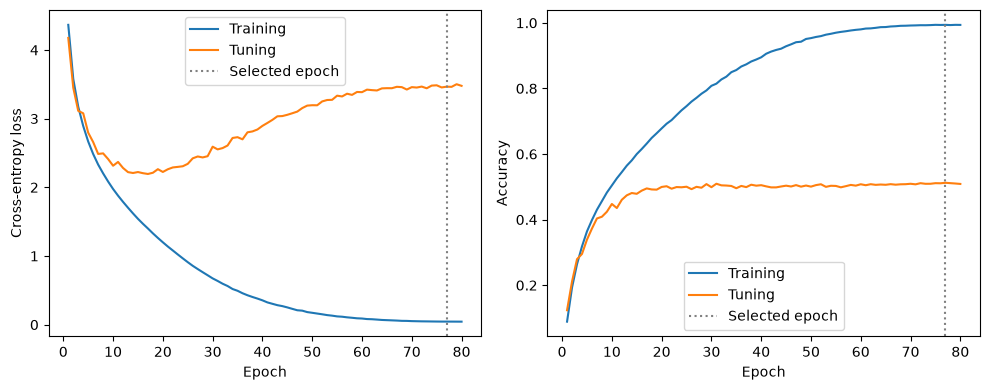

In [8]:
train_losses, train_scores, tune_losses, tune_scores = zip(*history)
epochs = range(1, len(history) + 1)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, train_values, tune_values, label in (
    (axes[0], train_losses, tune_losses, "Cross-entropy loss"),
    (axes[1], train_scores, tune_scores, "Accuracy"),
):
    ax.plot(epochs, train_values, label="Training")
    ax.plot(epochs, tune_values, label="Tuning")
    ax.axvline(best_epoch, linestyle=":", color="grey", label="Selected epoch")
    ax.set(xlabel="Epoch", ylabel=label)
    ax.legend()
fig.tight_layout()
plt.show()

## Final evaluation

Run the following cells once after model selection. The official validation split contains 50 images per class. Accuracy counts correct predictions across images. Macro F1 averages the class-specific F1 scores and gives each class equal weight.

In [9]:
official = load_dataset(DATASET_NAME, split="valid")
assert len(official) == 10_000
assert official.features["label"] == source_train.features["label"]
final_data = TinyImages(official, range(len(official)), mean=mean, std=std)
final_loader = DataLoader(final_data, batch_size=BATCH_SIZE, shuffle=False)

y_true, y_pred = [], []
model.eval()
with torch.inference_mode():
    for images, targets in final_loader:
        predictions = model(images.to(device)).argmax(dim=1).cpu()
        y_true.extend(targets.tolist())
        y_pred.extend(predictions.tolist())

assert len(y_true) == len(y_pred) == 10_000
assert np.array_equal(
    np.bincount(y_true, minlength=NUM_CLASSES), np.full(NUM_CLASSES, 50)
)

In [10]:
from sklearn.metrics import accuracy_score, f1_score

# y_true: true labels of the 10,000 evaluation images
# y_pred: your model's predicted labels for the same images
acc = accuracy_score(y_true, y_pred)
f1 = f1_score(y_true, y_pred, average="macro")

print(f"Evaluation accuracy: {acc:.4f}")
print(f"Evaluation macro F1: {f1:.4f}")

Evaluation accuracy: 0.5113
Evaluation macro F1: 0.5103
